In [ ]:
import os
from dotenv import load_dotenv

# Loads OPENAI_API_KEY / TAVILY_API_KEY / GOOGLE_API_KEY from the .env file
# in the project root. Never hardcode keys in this notebook.
load_dotenv()


                ┌───────────────┐
User Query ───► │ Claim Scorer  │
                └───────┬───────┘
                        │
               Score ≥ 70?
                │            │
               YES          NO
                │            │
         Direct Response   Domain Classifier
                                │
                        Domain Router
                                │
                  Trusted Domain Retriever
                                │
                         Answer Generator



In [ ]:
pip install langgraph langchain langchain-openai langchain-community faiss-cpu tavily-python


In [1]:
from typing import TypedDict, List
from langgraph.graph import StateGraph, END
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_community.vectorstores import FAISS
from langchain_community.tools.tavily_search import TavilySearchResults
from typing import TypedDict, Optional, List
import re


In [6]:
from langchain_ollama import ChatOllama



In [8]:

gen_llm = ChatOllama(model="qwen2.5:7b", 
                     temperature=0,num_ctx=8192)
critic_llm = ChatOllama(model="qwen2.5:7b", 
                     temperature=0,num_ctx=8192)
rag_llm = ChatOllama(model="qwen2.5:7b", 
                     temperature=0,num_ctx=8192)

In [10]:
class GraphState(TypedDict):
    query: str
    answer: str
    claims: List[str]
    domain: Optional[str]
    retrieved_docs: Optional[str]
    score: float
    iteration: int
    trusted_sources_used:Optional[List]
    # New Fields
    hallucination_rate: float
    unsupported_rate: float
    groundedness_score: float
    source_map: List[str]
    constraint_labels: Optional[List[str]]  #
    relevant_docs_found: bool
    is_fallback: bool

In [11]:
gen_prompt = ChatPromptTemplate.from_template(
"Answer the query:\n{query}"
)
generation_chain = gen_prompt | gen_llm | StrOutputParser()


In [12]:
def generate(state):
    ans = generation_chain.invoke({"query": state["query"]})
    return {"answer": ans, "iteration": 0}

In [13]:
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

claim_prompt = ChatPromptTemplate.from_template(
"""
You are an expert linguistic annotator. Your task is to decompose a complex text into a clean list of independent, verifiable atomic factual claims.

CRITICAL RULES FOR EXTRACTION (Based on FActScore Methodology):
1. Atomicity: Each claim must contain exactly ONE single verifiable fact. Break compound sentences into multiple separate claims.
2. Coreference Resolution (Decontextualization): You MUST replace all pronouns (he, she, it, they, this) with the explicit explicit entity names they refer to. A claim must make complete sense on its own without reading the rest of the text.
3. Exclude Fluff: Ignore conversational filler, opinions, subjective adjectives, and transitional phrases. Only extract objective factual statements.

EXAMPLE:
Text: "Apple Inc. was founded by Steve Jobs in 1976. It released the first iPhone in 2007, which revolutionized the industry."
Output:
1. Apple Inc. was founded by Steve Jobs.
2. Apple Inc. was founded in 1976.
3. Apple Inc. released the first iPhone in 2007.

Output STRICTLY a numbered list of claims. Do not include introductory or concluding text.

Answer to decompose:
{answer}
"""
)

claim_chain = claim_prompt | critic_llm | StrOutputParser()


In [14]:
def extract_claims(state):
    cl = claim_chain.invoke({"answer": state["answer"]})
    claims = [c for c in cl.split("\n") if c.strip()]
    return {"claims": claims}


In [15]:
LABEL_SCORES = {
    "CORRECT": 1.0,
    "INCORRECT": 0.0,
    "UNCERTAIN": 0.5
}

def parse_label(text):
    text = text.strip().upper()

    if "CORRECT" in text:
        return "CORRECT"
    if "INCORRECT" in text:
        return "INCORRECT"
    if "UNCERTAIN" in text:
        return "UNCERTAIN"

    return "UNCERTAIN"

In [16]:
from typing import List, Optional
# CHANGE THIS IMPORT:
from pydantic import BaseModel, Field 



In [17]:
# In v2 i have change the system prompt
from typing import Literal

# 1. Define the Schema for Constraint Checking
class ConstraintVerdict(BaseModel):
    claim_id: int = Field(description="The index of the claim being checked")
    verdict: Literal["PASS", "VIOLATION"] = Field(description="'VIOLATION' if the claim breaks a query constraint (e.g. time range), otherwise 'PASS'")
    reason: str = Field(description="Brief reason for the verdict")

class ConstraintCheckResult(BaseModel):
    checks: List[ConstraintVerdict] = Field(description="List of verdicts for all claims")

# 2. Define the Node Function
def check_constraints(state):
    query = state["query"]
    claims = state["claims"]
    
    if not claims:
        return {"constraint_labels": []}

    # Setup the structured LLM
    structured_checker = critic_llm.with_structured_output(ConstraintCheckResult)

    formatted_claims = "\n".join([f"{i}. {claim}" for i, claim in enumerate(claims)])

    system_prompt = """
    You are an Expert Query Constraint Validator. Your task is to rigorously evaluate whether generated claims respect the explicit and implicit constraints of the user's original query.

    STEP 1: Analyze the User Query to identify all applied constraints from the following categories:
    - Temporal Constraints: Exact dates, tight date ranges (e.g., "1750-1850"), or relative time expressions (e.g., "current", "latest", "prior to 1990").
    - Spatial/Geographic Constraints: Specific cities, countries, or regions.
    - Negative/Exclusionary Constraints: Explicit instructions to omit something (e.g., "without mentioning X", "excluding cases from NY").
    - Factual/Premise Constraints: Check if the query assumes a false or logically impossible premise (e.g., "What are the health benefits of eating glass?").
    - Domain Specificity: Does the query require adherence to a specific professional standard (e.g., strict legal rulings, medical consensus)?

    STEP 2: Check each generated Claim against these identified constraints.

    CRITICAL RULES:
    1. Temporal/Spatial Mismatch: If a claim is historically or factually true but occurred outside the query's specified timeframe or location, label it VIOLATION. (Example: Query asks for "1750-1850". Claim says "Founded in 1875". -> VIOLATION).
    2. False Premises: If the query contains a fictional or myth-based premise, any claim that treats that premise as a real, factual event is a VIOLATION. 
    3. Negative Constraint Breach: If a claim includes an entity the query explicitly asked to exclude, label it VIOLATION.
    4. If the query has no specific constraints, or the claim perfectly aligns with all identified constraints, label it PASS.

    Return a valid JSON object with verdicts ('PASS' or 'VIOLATION') and a brief 'reason' for each claim.
    """

    user_prompt = f"""
    User Query: "{query}"

    Claims to Check:
    {formatted_claims}

    Evaluate each claim and return the JSON.
    """

    prompt = ChatPromptTemplate.from_messages([
        ("system", system_prompt),
        ("human", user_prompt)
    ])

    # Run the check
    try:
        chain = prompt | structured_checker
        result = chain.invoke({})
        verdicts = result.checks
    except Exception as e:
        print(f"Constraint check failed: {e}")
        # Default to PASS if check fails to avoid breaking the flow
        return {"constraint_labels": ["PASS"] * len(claims)}

    # Map results to a list matching the claims order
    verdict_map = {v.claim_id: v.verdict for v in verdicts}
    constraint_labels = [verdict_map.get(i, "PASS") for i in range(len(claims))]

    return {"constraint_labels": constraint_labels}

In [18]:
def route_after_constraints(state):
    """
    Routes to scoring if all claims PASS, 
    otherwise skips to domain detection for a web search.
    """
    labels = state.get("constraint_labels", [])
    
    if state["iteration"] >= 3:
        return "stop"
    if any(label == "VIOLATION" for label in labels):
        # If even one claim violates the query constraints, 
        # skip scoring and go straight to fixing it via search.
        return "detect_domain"
    
    return "score_intrinsic"

In [19]:
from typing import List
from pydantic import BaseModel, Field
from langchain_core.prompts import ChatPromptTemplate

# --- Upgraded Data Structures ---
class ClaimJudgment(BaseModel):
    claim_id: int = Field(description="The index of the claim being evaluated (0-based)")
    reasoning: str = Field(description="A brief 1-sentence explanation of exactly what makes the claim supported, contradicted, or unverifiable based on the context.")
    label: str = Field(description="Strictly one of: CORRECT, INCORRECT, PARTIAL")

class BatchVerificationResult(BaseModel):
    judgments: List[ClaimJudgment] = Field(description="List of rigorous judgments for all claims")

# --- The Updated Function ---
def score_claims_batch(state):
    """
    Scores claims in a batch, respecting constraint checks.
    If a claim failed the constraint check (VIOLATION), it is automatically marked 0.0 (INCORRECT).
    Only 'PASS' claims are sent to the LLM for rigorous FActScore/HaluEval factual verification.
    """
    
    # 1. Setup the structured critic
    structured_critic = critic_llm.with_structured_output(BatchVerificationResult)

    claims = state.get("claims", [])
    retrieved_docs = state.get("retrieved_docs", "")
    constraint_labels = state.get("constraint_labels", [])
    
    if not claims:
        return {
            "score": 0.0,
            "hallucination_rate": 0.0,
            "unsupported_rate": 0.0,
            "groundedness_score": 0.0,
            "labels": []
        }

    # 2. Validation: Ensure constraint_labels matches claims length
    if not constraint_labels or len(constraint_labels) != len(claims):
        # Default to PASS if constraints weren't checked
        constraint_labels = ["PASS"] * len(claims)

    # 3. Filter: Identify which claims need verification
    # We only verify claims that PASSED the constraint check.
    claims_to_verify_indices = [i for i, label in enumerate(constraint_labels) if label == "PASS"]
    
    # Initialize all scores to 0.0 (INCORRECT). 
    # This automatically handles the constraint VIOLATION cases efficiently!
    numeric_scores = [0.0] * len(claims)
    
    # 4. Run LLM Verification (Only if we have claims to verify)
    if claims_to_verify_indices:
        # subset the claims list
        claims_to_verify = [claims[i] for i in claims_to_verify_indices]
        
        formatted_claims = "\n".join([f"{i}. {claim}" for i, claim in enumerate(claims_to_verify)])

        # THE RIGOROUS ACADEMIC PROMPT
        system_prompt = """
        You are an Expert Fact-Checker and Hallucination Evaluator. Your task is to rigorously evaluate a list of atomic claims against the provided context.

        CRITICAL EVALUATION RULES (Based on FActScore and HaluEval methodologies):
        1. Strict Entailment (Label: CORRECT): The claim is completely, explicitly supported by established facts in the provided context. 
        2. Extrinsic Hallucination / Unverifiable (Label: INCORRECT): The claim introduces novel, specific details (names, dates, statistics) that cannot be verified by the context. Plausible guesses are NOT facts.
        3. Intrinsic Hallucination / Contradiction (Label: INCORRECT): The claim directly contradicts the provided context.
        4. Partial / Vague Truth (Label: PARTIAL): The claim is broadly true but lacks necessary precision, or contains a mix of verified and unverified information within the same atomic statement.

        EVALUATION HEURISTIC:
        - If a claim says "The iPhone 14 was released in 2022 and features a USB-C port," and the USB-C part is false or missing in context, the ENTIRE claim must be penalized.

        Think carefully, provide a 1-sentence reasoning, and then assign the strict label.
        """

        user_prompt = f"""
        Context:
        {retrieved_docs}

        Claims to Verify:
        {formatted_claims}
        """

        prompt = ChatPromptTemplate.from_messages([
            ("system", system_prompt),
            ("human", user_prompt)
        ])

        chain = prompt | structured_critic
        
        try:
            result = chain.invoke({})
            judgments = result.judgments
        except Exception as e:
            print(f"Batch verification failed: {e}")
            judgments = []

        # 5. Merge Logic: Map sub-list results back to the main list
        # Map {local_index -> label}
        judgment_map = {j.claim_id: j.label.upper() for j in judgments}
        
        for local_idx, global_idx in enumerate(claims_to_verify_indices):
            label = judgment_map.get(local_idx, "PARTIAL")
            
            # Map strict labels to numerical scores
            if "CORRECT" in label and "INCORRECT" not in label:
                numeric_scores[global_idx] = 1.0
            elif "INCORRECT" in label:
                numeric_scores[global_idx] = 0.0
            else:
                numeric_scores[global_idx] = 0.5 # Maps PARTIAL to 0.5
    
    # 6. Calculate Metrics (using the full numeric_scores list)
    total = len(numeric_scores)
    contradicted = numeric_scores.count(0.0)
    unsupported = numeric_scores.count(0.5)
    supported = numeric_scores.count(1.0)

    hallucination_rate = (contradicted / total) * 100 if total > 0 else 0
    unsupported_rate = (unsupported / total) * 100 if total > 0 else 0
    groundedness_score = (supported / total) * 100 if total > 0 else 0
    final_score = (sum(numeric_scores) / total) * 100 if total > 0 else 0

    return {
        "score": final_score,
        "labels": numeric_scores,
        "hallucination_rate": hallucination_rate,
        "unsupported_rate": unsupported_rate,
        "groundedness_score": groundedness_score
    }


In [20]:
# Re-use the Pydantic models defined earlier (ClaimJudgment, BatchVerificationResult)


# --- The Updated Function ---
def score_claims_batch_only_LLM(state):
    """
    Evaluates claims using ONLY the LLM's internal parametric knowledge.
    Acts as an initial filter: if the LLM is absolutely certain a claim is false or unsupported,
    it triggers the routing to external RAG retrieval.
    """
    
    # 1. Setup the structured critic
    structured_critic = critic_llm.with_structured_output(BatchVerificationResult)

    claims = state.get("claims", [])
    
    if not claims:
        return {
            "score": 0.0,
            "hallucination_rate": 0.0,
            "unsupported_rate": 0.0,
            "groundedness_score": 0.0,
            "labels": []
        }

    # 2. Format claims for the prompt
    formatted_claims = "\n".join([f"{i}. {claim}" for i, claim in enumerate(claims)])

    # 3. Define the Batch Prompt for Intrinsic Knowledge (Zero-Shot)
    system_prompt = """
    You are an Expert Fact-Checker evaluating AI-generated claims. 
    You must determine if each claim is factually correct based ONLY on your internal, universally established knowledge (Parametric Knowledge).

    CRITICAL RULES FOR CLOSED-BOOK EVALUATION:
    1. Label 'CORRECT' (Score 1.0): The claim is a universally accepted historical, scientific, or factual truth. You are 100% certain.
    2. Label 'INCORRECT' (Score 0.0): The claim directly contradicts established facts (Intrinsic Hallucination). 
    3. Label 'UNCERTAIN' (Score 0.5): The claim contains highly specific details (niche statistics, exact recent dates, obscure names) or is plausible but cannot be stated as an absolute fact without external search (Extrinsic Hallucination). 

    HEURISTIC:
    - If a claim states "Water boils at 100°C at sea level", label it CORRECT.
    - If a claim states "The GDP of Bhutan in 2023 was exactly $2.89 billion", label it UNCERTAIN (do not guess exact statistics).
    - If a claim states "Abraham Lincoln was born in 1950", label it INCORRECT.

    Do NOT guess. If you need a search engine to verify the specifics, you MUST label it UNCERTAIN.
    Provide a 1-sentence reasoning before assigning your label.
    """

    user_prompt = f"""
    Claims to Verify (Closed-Book):
    {formatted_claims}
    """

    prompt = ChatPromptTemplate.from_messages([
        ("system", system_prompt),
        ("human", user_prompt)
    ])

    # 4. Run the Batch Verification
    chain = prompt | structured_critic
    
    try:
        result = chain.invoke({})
        judgments = result.judgments
    except Exception as e:
        print(f"Batch intrinsic verification failed: {e}")
        judgments = []

    # 5. Process Results (Map to scores)
    judgment_map = {j.claim_id: j.label.upper() for j in judgments}
    numeric_scores = []
    
    for i in range(len(claims)):
        label = judgment_map.get(i, "UNCERTAIN")
        
        # Map strict labels to numerical scores
        if "CORRECT" in label and "INCORRECT" not in label:
            numeric_scores.append(1.0)
        elif "INCORRECT" in label:
            numeric_scores.append(0.0)
        else:
            numeric_scores.append(0.5) # UNCERTAIN maps to 0.5

    # 6. Calculate Metrics
    total = len(numeric_scores)
    contradicted = numeric_scores.count(0.0)
    unsupported = numeric_scores.count(0.5)
    supported = numeric_scores.count(1.0)

    hallucination_rate = (contradicted / total) * 100 if total > 0 else 0
    unsupported_rate = (unsupported / total) * 100 if total > 0 else 0
    groundedness_score = (supported / total) * 100 if total > 0 else 0
    final_score = (sum(numeric_scores) / total) * 100 if total > 0 else 0

    return {
        "score": final_score,
        "labels": numeric_scores,
        "hallucination_rate": hallucination_rate,
        "unsupported_rate": unsupported_rate,
        "groundedness_score": groundedness_score
    }

In [21]:
TRUSTED_SOURCES = {
    "law": [
        "indiankanoon.org",     # India Case Law & Statutes
        "prsindia.org",         # Indian Bills & Parliamentary tracking
        "law.cornell.edu",      # US Federal & State Law / Supreme Court
        "casemine.com",         # US/UK/India Case Law
        "legislation.gov.uk",   # United Kingdom official law
        "eur-lex.europa.eu"     # European Union law
    ],
    "engineering": [
        "arxiv.org",            # Open-access CS/Math/Physics/EE
        "engineering.com",      # General engineering concepts
        "techxplore.com",       # Engineering & Tech news/breakthroughs
        "sciencedaily.com"      # Broad scientific and engineering research
    ],
    "history": [
        "britannica.com",       # Global encyclopedic history
        "worldhistory.org",     # Excellent open-access global history
        "archives.gov",         # US History
        "nationalarchives.gov.uk", # UK/European History
        "gutenberg.org"         # Primary historical texts and literature
    ],
    "medical": [
        "ncbi.nlm.nih.gov/pmc", # PubMed Central (FREE full text research)
        "who.int",              # World Health Organization (Global health)
        "mayoclinic.org",       # Consumer-friendly diagnostics
        "clevelandclinic.org",  # Excellent structured medical info
        "nhs.uk"                # UK National Health Service (great plain-language medical)
    ],
    "finance": [
        "investopedia.com",     # Financial definitions and concepts
        "imf.org",              # International Monetary Fund (Global econ)
        "worldbank.org",        # Global economic data
        "rbi.org.in",           # Reserve Bank of India
        "bloomberg.com"         # Global market news
    ],
    "science": [
        "nature.com",           # Top-tier scientific journal
        "science.org",          # AAAS Science journal
        "nasa.gov",             # Space and astrophysics
        "phys.org"              # Physics, earth science, and bio
    ],
    "general": [
        "britannica.com",
        "wikipedia.org",
        "reuters.com",          # Unbiased global news
        "apnews.com",           # Unbiased global news
        "bbc.com"               # Global perspective news
    ]
}

In [22]:
from pydantic import BaseModel, Field
from langchain_core.prompts import ChatPromptTemplate

# 1. Define the Structured Output schema
class DomainClassification(BaseModel):
    domain: str = Field(
        description="The classified domain name. Must perfectly match one of the provided options."
    )

# 2. Define the Prompt globally to save initialization overhead
DOMAIN_SYSTEM_PROMPT = """You are a highly accurate query router. 
Classify the user's query into EXACTLY ONE of the following domains:
{options}

If the query does not strongly fit into one of the specific domains, classify it as 'general'."""

DOMAIN_PROMPT = ChatPromptTemplate.from_messages([
    ("system", DOMAIN_SYSTEM_PROMPT),
    ("human", "Query: {query}")
])

def detect_domain(state):
    """
    Analyzes the query and routes it to the appropriate domain category.
    Optimized with Structured Outputs to guarantee valid dictionary keys.
    """
    # print("---DETECTING DOMAIN---")
    
    query = state.get("query", "")
    if not query:
        return {"domain": "general"}
        
    # Dynamically grab the keys from your TRUSTED_SOURCES dictionary
    options = ", ".join(TRUSTED_SOURCES.keys())
    
    try:
        # 3. Bind the Pydantic model to your LLM (ensure gen_llm is globally available)
        structured_classifier = gen_llm.with_structured_output(DomainClassification)
        chain = DOMAIN_PROMPT | structured_classifier
        
        # Execute the chain
        result = chain.invoke({
            "options": options, 
            "query": query
        })
        
        # Clean the output just in case
        domain = result.domain.strip().lower()
        
        # 4. Final safety check: if the LLM hallucinated a category, catch it
        if domain not in TRUSTED_SOURCES:
            # print(f"   [Warning]: LLM returned invalid domain '{domain}'. Defaulting to 'general'.")
            domain = "general"
            
    except Exception as e:
        # print(f"   [Classification Error]: {e}. Defaulting to 'general'.")
        domain = "general"

    # print(f"   [Classified Domain]: {domain}")
    return {"domain": domain}

In [42]:
from pydantic import BaseModel, Field
from langchain_core.prompts import ChatPromptTemplate
from langchain_tavily import TavilySearch

# 1. Define the Expected Output for the Rewriter
class SearchQuery(BaseModel):
    optimized_query: str = Field(description="The optimized keyword search string")

# 2. Set up the Rewriter Prompt
REWRITE_SYSTEM = """You are an expert search query optimizer. 
Convert the user's conversational question into a highly effective, keyword-dense search engine query. 
Remove conversational filler. Keep vital constraints like dates, locations, and proper nouns.
If the question is already short and optimal, return it as is."""

REWRITE_PROMPT = ChatPromptTemplate.from_messages([
    ("system", REWRITE_SYSTEM),
    ("human", "Original Query: {query}")
])

# 3. Initialize Tavily
SEARCH_TOOL = TavilySearch(
    tavily_api_key=os.getenv("TAVILY_API_KEY"),
    search_depth="advanced", 
    max_results=5
)

def trusted_search(state):
    # print("---OPTIMIZING QUERY AND SEARCHING TRUSTED SOURCES---")
    
    original_query = state.get("query", "")
    domain = state.get("domain", "general")

    if not original_query:
        return {"retrieved_docs": "No query provided.", "trusted_sources_used": []}

    allowed_domains = TRUSTED_SOURCES.get(domain, TRUSTED_SOURCES.get("general", []))

    if not allowed_domains:
        return {
            "retrieved_docs": "No trusted sources configured for this domain.", 
            "trusted_sources_used": []
        }

    # STEP 1: REWRITE THE QUERY (WITH SMART BYPASS)
    word_count = len(original_query.split())
    
    # If the query is 5 words or less, bypass the LLM to save time/latency
    if word_count < 6:
        # print(f"   [Original]:  {original_query}")
        # print("   [Query is short: Skipping rewrite to save time]")
        optimized_query = original_query
    else:
        try:
            # Bind the Pydantic model to your LLM (make sure critic_llm is defined in your script)
            structured_rewriter = critic_llm.with_structured_output(SearchQuery)
            rewrite_chain = REWRITE_PROMPT | structured_rewriter
            
            result = rewrite_chain.invoke({"query": original_query})
            optimized_query = result.optimized_query
            
            print(f"   [Original]:  {original_query}")
            print(f"   [Optimized]: {optimized_query}")
        except Exception as e:
            # print(f"   [Query Rewrite Failed, using original]: {e}")
            optimized_query = original_query

    # STEP 2: EXECUTE SEARCH WITH OPTIMIZED QUERY
    try:
        results = SEARCH_TOOL.invoke({
            "query": optimized_query, # Use the new, clean query!
            "include_domains": allowed_domains # Keep the strict domain firewall
        })

        if not results:
            return {
                "retrieved_docs": "No documents found in trusted sources.", 
                "trusted_sources_used": allowed_domains

            }
        if isinstance(results, dict) and "results" in results:
            docs_list = results["results"]
        elif isinstance(results, list):
            docs_list = results
        else:
            docs_list = []

        # FORMAT FOR THE GRADER
        context_blocks = []
        for r in docs_list:
            if isinstance(r, dict) and "content" in r:
                url = r.get("url", "Unknown")
                content = r["content"]
                context_blocks.append(f"Source: {url}\n{content}")
        
        context = "\n\n".join(context_blocks) if context_blocks else "No documents found in trusted sources."

        return {
            "retrieved_docs": context,
            "trusted_sources_used": allowed_domains,
            "is_fallback": False # <--- Add this!

        }
        
    except Exception as e:
        print(f"   [Search API Error]: {e}")
        return {
            "retrieved_docs": "No relevant context found from trusted sources.",
            "trusted_sources_used": allowed_domains
        }

In [24]:
from pydantic import BaseModel, Field
from langchain_core.prompts import ChatPromptTemplate

class DocumentGrader(BaseModel):
    binary_score: str = Field(description="Relevance score 'yes' or 'no'")
    reasoning: str = Field(description="1 sentence explaining why it is relevant or irrelevant")

SYSTEM_PROMPT = """You are a strict relevance grader assessing retrieved web documents for a research pipeline.
CRITICAL RULES:
1. If the document contains factual information, keywords, or semantic meaning that helps answer the user query, grade 'yes'.
2. If the document is a paywall notice, a login screen, a cookie acceptance text, or completely off-topic, grade 'no'.
3. If the document is from a legal/medical domain but discusses an entirely different case/disease, grade 'no'.
"""

GRADE_PROMPT = ChatPromptTemplate.from_messages([
    ("system", SYSTEM_PROMPT),
    ("human", "User query: {query}\n\nRetrieved document:\n{document}")
])

def grade_documents(state):
    """
    Evaluates retrieved documents. Sets 'relevant_docs_found' flag for downstream routing.
    """
    # print("---GRADING RETRIEVED DOCUMENTS---")
    query = state.get("query", "")
    retrieved_docs_str = state.get("retrieved_docs", "")

    # Early exit if there are no docs to grade
    if not retrieved_docs_str or retrieved_docs_str in ("No documents found.", "No relevant context found from trusted sources."):
        return {"retrieved_docs": "No relevant context found.", "relevant_docs_found": False}

    raw_docs = [doc.strip() for doc in retrieved_docs_str.split("Source: ") if doc.strip()]
    full_docs = [f"Source: {doc}" for doc in raw_docs]

    if not full_docs:
         return {"retrieved_docs": "No relevant context found.", "relevant_docs_found": False}

    structured_grader = critic_llm.with_structured_output(DocumentGrader)
    retrieval_grader = GRADE_PROMPT | structured_grader

    batch_inputs = [{"query": query, "document": doc} for doc in full_docs]
    filtered_docs = []
    
    try:
        results = retrieval_grader.batch(batch_inputs, return_exceptions=True)
    except Exception as e:
        # print(f"   [Grader Error, keeping all docs]: {e}")
        return {"retrieved_docs": "\n\n".join(full_docs), "relevant_docs_found": True}

    for doc, result in zip(full_docs, results):
        if isinstance(result, Exception):
            filtered_docs.append(doc)
        elif result.binary_score.lower() == "yes":
            filtered_docs.append(doc)
        else:
            print(f"   [Filtered Out]: {result.reasoning}")

    # ROUTING LOGIC UPDATE: Determine what flag to send to the LangGraph edge
    if not filtered_docs:
        # print("   [CRAG Warning]: All retrieved documents were graded as irrelevant. Routing to fallback search.")
        return {
            "retrieved_docs": "No relevant context found from trusted sources.", 
            "relevant_docs_found": False # Graph will route to general_web_search
        }
    else:
        # print(f"   [CRAG Success]: Kept {len(filtered_docs)} relevant documents. Routing to generator.")
        return {
            "retrieved_docs": "\n\n".join(filtered_docs), 
            "relevant_docs_found": True # Graph will route to regenerate
        }

In [25]:
def route_after_grading(state):
    # print("---ROUTING AFTER GRADING---")
    
    if state.get("relevant_docs_found", False):
        # print("   [Decision]: Relevant docs exist -> Routing to regenerate")
        return "regenerate"
        
    # CIRCUIT BREAKER: If we already did the fallback search and it failed,
    # skip regeneration and scoring. Go straight to the apology.
    if state.get("iteration", 0) > 0:
        # print("   [Decision]: All searches failed. Routing to apology early exit.")
        return "generate_apology"
        
    else:
        # print("   [Decision]: Trusted docs failed. Routing to general_web_search")
        return "general_web_search"

In [26]:
# if context is not related to questing like amu que ,first context regected by regenerate node like amu ques and then it get less score, finally after 3 itr it get very loc score
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

# 1. Move prompt and chain initialization OUTSIDE the function
# This prevents LangGraph from rebuilding the prompt template and chain 
# from scratch on every single graph iteration, saving CPU time.

REGENERATE_PROMPT = ChatPromptTemplate.from_template(
    """You are an expert research assistant. 
Answer the user's question using ONLY the provided context below. 

CRITICAL RULES:
1. If the context does not contain the answer, truthfully say "I don't have enough information to answer that based on the retrieved trusted sources." Do not guess.
2. The context includes "Source:" URLs. When you state a fact, cite the source URL it came from at the end of the sentence or paragraph.

Context:
{context}

Question:
{question}
"""
)

# Initialize the chain globally (ensure rag_llm is defined in your environment)
REGENERATE_CHAIN = REGENERATE_PROMPT | rag_llm | StrOutputParser()

def regenerate(state):
    """
    Generates the final answer using retrieved context.
    Optimized for LangGraph execution and source citation.
    """
    # print("---GENERATING ANSWER---")
    
    # 2. Safely access state variables using .get() to prevent hard crashes
    question = state.get("query", "")
    context = state.get("retrieved_docs", "No context provided.")
    
    # NOTE: Ensure your state key matches here! 
    # In earlier steps you used "iter", but here you used "iteration". 
    # I am using "iteration" as you wrote, but make sure it matches your TypedDict!
    current_iteration = state.get("iteration", 0) 
    
    if not question:
        return {"answer": "No question was provided.", "iteration": current_iteration + 1}

    # 3. Execute Generation with Error Handling
    try:
        ans = REGENERATE_CHAIN.invoke({
            "context": context,
            "question": question
        })
    except Exception as e:
        # print(f"   [Generator Error]: {e}")
        ans = "I encountered a generation error while trying to formulate the final answer."

    return {
        "answer": ans,
        "iteration": current_iteration + 1
    }


In [27]:
def route_on_score(state):
    """
    Conditional edge routing function with a two-tiered fallback circuit breaker.
    """
    # print("---ROUTING ON SCORE---")
    
    score = state.get("score", 0)
    current_iteration = state.get("iteration", 0)
    
    # print(f"   [Current Score]: {score}/100 | [Iteration]: {current_iteration}")

    if score >= 70:
        # print("   [Decision]: Score is passing. Routing to generate_answer.")
        return "generate_answer"
        
    elif current_iteration < 2:
        # print("   [Decision]: Score is too low. Routing back to trusted_search for trusted retrieval.")
        return "trusted_search"
        
    elif current_iteration == 2:
        # TIER 1: The trusted search loops failed. Give it one chance on the open web.
        # print("   [Decision]: Max trusted iterations reached. Falling back to general_web_search.")
        return "general_web_search"
        
    else:
        # TIER 2: The open web search also failed. Stop the graph.
        # print("   [Decision]: General web search also failed. Stopping graph to prevent infinite loop.")
        return "stop"

In [40]:
from langchain_tavily import TavilySearch

# NEW CLASS NAME
WEB_TOOL = TavilySearch(
    tavily_api_key=os.getenv("TAVILY_API_KEY"),
    search_depth="advanced", 
    max_results=5
)
def general_web_search(state):
    # print("---GENERAL WEB SEARCH (FALLBACK)---")
    
    query = state.get("query", "")
    current_iter = state.get("iteration", 0)
    
    if not query:
        return {"retrieved_docs": "No query provided.", "iteration": current_iter + 1}
         
    try:
        web_docs = WEB_TOOL.invoke(query)
        
        # --- THE FIX: Extract the actual list from the dictionary ---
        if isinstance(web_docs, dict) and "results" in web_docs:
            docs_list = web_docs["results"]
        elif isinstance(web_docs, list):
            docs_list = web_docs
        else:
            docs_list = []
            
        # Format the fallback docs clearly
        context_blocks = []
        for w in docs_list:
            if isinstance(w, dict) and "content" in w:
                url = w.get("url", "Unknown")
                content = w["content"]
                context_blocks.append(f"Source: {url}\n{content}")
        
        context = "\n\n".join(context_blocks) if context_blocks else "No fallback documents found."
            
    except Exception as e:
        print(f"   [Web Search Error]: {e}")
        context = "Failed to retrieve fallback documents."

    return {
        "retrieved_docs": context,
        "iteration": current_iter + 1,
        "is_fallback": True # <--- Add this!
    }

In [29]:


def route_after_constraints_regen(state):
    """
    Conditional edge routing function for regenerated constraints 
    with a two-tiered fallback circuit breaker.
    """
    # print("---ROUTING AFTER REGEN CONSTRAINTS---")
    
    labels = state.get("constraint_labels", [])
    current_iteration = state.get("iteration", 0)
    
    # print(f"   [Constraints]: {labels} | [Iteration]: {current_iteration}")

    # SUCCESS: No violations found
    if "VIOLATION" not in labels:
        # print("   [Decision]: All constraints passed. Routing to score_retrieved.")
        return "score_retrieved"
        
    # FAIL TIER 0: Try trusted search again
    elif current_iteration < 2:
        # print("   [Decision]: Constraints violated. Routing back to trusted_search.")
        return "trusted_search"
        
    # FAIL TIER 1: Trusted loops exhausted. Try general web search.
    elif current_iteration == 2:
        # print("   [Decision]: Max trusted iterations reached with violations. Falling back to general_web_search.")
        return "general_web_search"
        
    # FAIL TIER 2: General search exhausted. Stop the graph.
    else:
        # print("   [Decision]: General web search constraints also violated. Stopping graph to prevent infinite loop.")
        return "stop"

In [30]:
def route_on_score_intrinsic(state):
    """
    Conditional edge routing function with a two-tiered fallback circuit breaker.
    """
    # print("---ROUTING ON SCORE---")
    
    score = state.get("score", 0)
    current_iteration = state.get("iteration", 0)
    
    # print(f"   [Current Score]: {score}/100 | [Iteration]: {current_iteration}")

    if score >= 70:
        # print("   [Decision]: Score is passing. Routing to generate_answer.")
        return "generate_answer"
        
    else:
        # TIER 2: The open web search also failed. Stop the graph.
        # print("   [Decision]: Score is failed. Routing to detect_domain.")
        return "detect_domain"

In [31]:
def generate_apology(state):
    """
    Early exit node that bypasses the LLM generator and scorer
    when all searches fail.
    """
    print("---GENERATING APOLOGY (EARLY EXIT)---")
    return {
        "answer": "I don't have enough information to answer that based on the retrieved trusted sources."
    }

### we can also add local database , domain routing : after domain detection do routing

In [32]:
builder = StateGraph(GraphState)

# Nodes
builder.add_node("generate", generate)
builder.add_node("extract_claims_initial", extract_claims)
builder.add_node("check_constraints", check_constraints)
builder.add_node("score_intrinsic", score_claims_batch_only_LLM) 
builder.add_node("detect_domain", detect_domain)
builder.add_node("general_web_search", general_web_search) 
builder.add_node("trusted_search", trusted_search)
builder.add_node("regenerate", regenerate)
builder.add_node("check_constraints_regen", check_constraints)
builder.add_node("grade_documents", grade_documents)
builder.add_node("extract_claims_regen", extract_claims)
builder.add_node("score_retrieved", score_claims_batch) 
builder.add_node("generate_apology", generate_apology)

# Entry
builder.set_entry_point("generate")

builder.add_edge("generate", "extract_claims_initial")
builder.add_edge("extract_claims_initial", "check_constraints")
builder.add_conditional_edges(
    "check_constraints",
    route_after_constraints,
    {
        "score_intrinsic": "score_intrinsic",
        "detect_domain": "detect_domain",
        "stop": END
    }
)

builder.add_conditional_edges(
    "score_intrinsic",
    route_on_score_intrinsic,
    {
        "generate_answer": END,
        "detect_domain": "detect_domain",
    }
)

builder.add_edge("detect_domain", "trusted_search")
builder.add_edge("trusted_search", "grade_documents")
builder.add_conditional_edges(
    "grade_documents",
    route_after_grading,
    {
        "regenerate": "regenerate",
        "general_web_search": "general_web_search",
        "generate_apology": "generate_apology" # <--- New mapping
    }
)
builder.add_edge("generate_apology", END)
builder.add_edge("general_web_search", "grade_documents")
builder.add_edge("regenerate", "extract_claims_regen")
builder.add_edge("extract_claims_regen", "check_constraints_regen")
builder.add_conditional_edges(
    "check_constraints_regen",
    route_after_constraints_regen, 
    {
        "score_retrieved": "score_retrieved", 
        "trusted_search": "trusted_search",         # <--- Loop back to trusted
        "general_web_search": "general_web_search", # <--- Fallback to general
        "stop": END                                 # <--- Circuit breaker
    }
)

builder.add_conditional_edges(
    "score_retrieved",
    route_on_score,
    {
        "generate_answer": END,
        "trusted_search": "trusted_search",
        "general_web_search": "general_web_search", # <--- Add this new mapping!
        "stop": END
    }
)

graph = builder.compile()


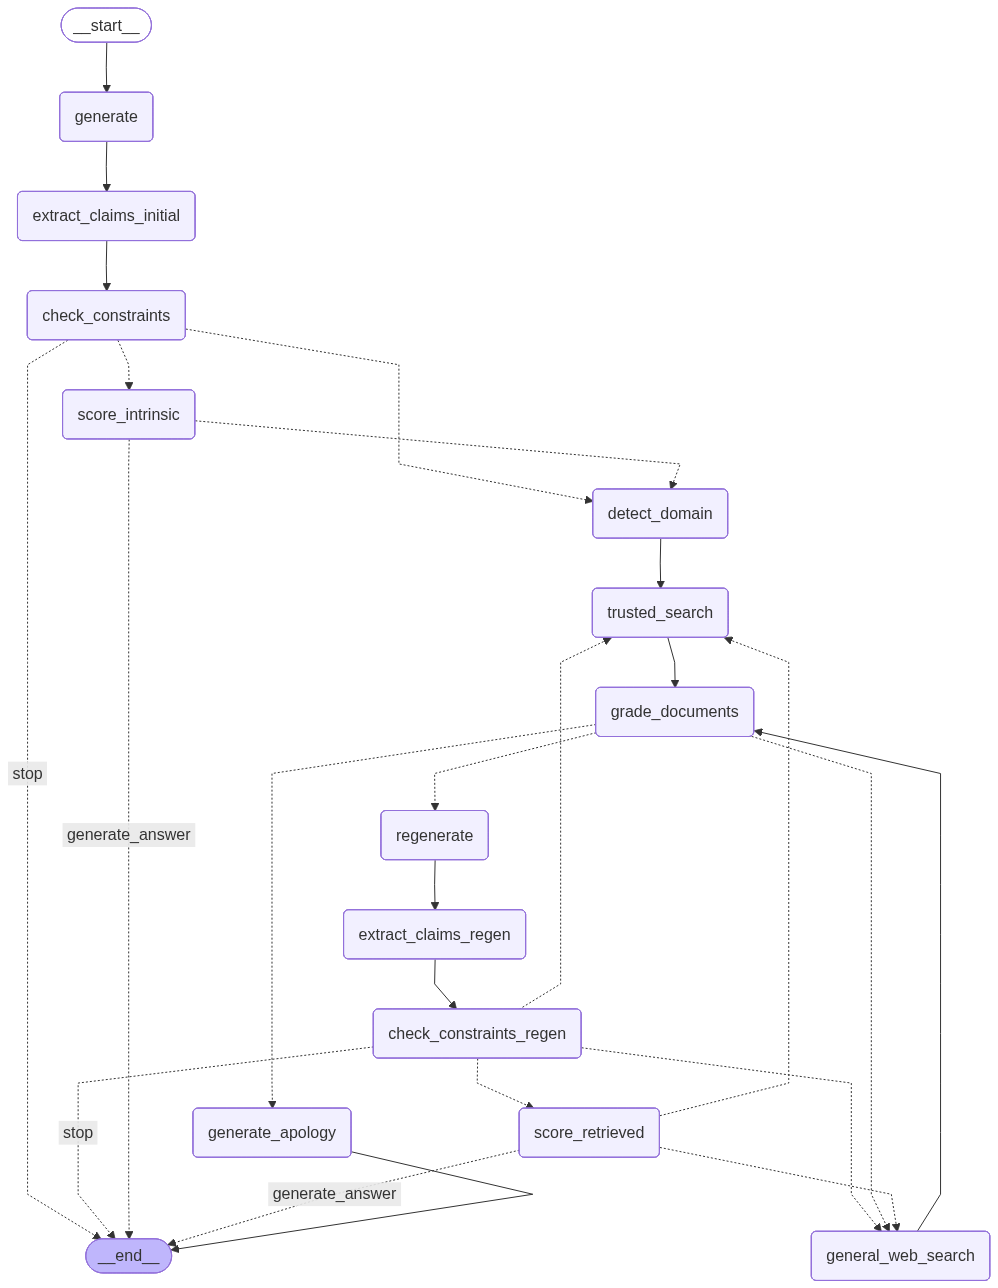

In [33]:
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))


To improve this we need to extract info correlcty , the answer are not proper because web seacrch and soucre website are not proper

In [35]:
final_state = graph.invoke({"query": "Explain how insulin regulates blood sugar"})

# 1. Print the generated answer
print("\nFinal Answer:\n", final_state["answer"])

# 2. Check the flag and print the warning!
if final_state.get("is_fallback", False):
    print("\n⚠️ SYSTEM FLAG: The trusted databases lacked sufficient information. This answer was generated using a general web search and the sources may not be authentic.")


Final Answer:
 Insulin is a hormone produced by the beta cells of the pancreas and plays a crucial role in regulating blood glucose (sugar) levels. Here’s an overview of how insulin works to maintain normal blood sugar levels:

1. **Release of Insulin**: When you eat food, particularly carbohydrates, your body breaks down these foods into simple sugars, primarily glucose. The presence of glucose in the bloodstream triggers the release of insulin from the beta cells in the pancreas.

2. **Insulin's Effect on Cells**:
   - **Liver and Muscle Cells**: Insulin promotes the uptake of glucose by liver and muscle cells through the activation of specific transporters (GLUT4). Once inside these cells, glucose is used for energy or stored as glycogen.
   - **Fat Cells**: Insulin also facilitates the storage of excess glucose in fat cells as triglycerides.

3. **Inhibition of Glucose Production**:
   - In the liver, insulin inhibits the production and release of glucose into the bloodstream thro

In [31]:
graph.invoke({"query": "What is the name of the first animal to land on the moon?"})

   [Original]:  What is the name of the first animal to land on the moon?
   [Optimized]: first animal land on moon name
   [Filtered Out]: The document discusses various animals sent into space but does not provide the name of the first animal to land on the moon.
   [Filtered Out]: The document discusses myths and stories related to animals and the Moon but does not provide factual information about the first animal to land on the Moon.
   [Filtered Out]: The document does not provide the name of the first animal to land on the moon, as it discusses various space milestones without mentioning any animal landing on the moon.
   [Original]:  What is the name of the first animal to land on the moon?
   [Optimized]: first animal land on moon name
   [Filtered Out]: The document discusses various animals sent into space but does not provide the name of the first animal to land on the moon.
   [Filtered Out]: The document discusses myths and stories related to animals and the Moon but does

{'query': 'What is the name of the first animal to land on the moon?',
 'answer': "I don't have enough information to answer that based on the retrieved trusted sources.",
 'claims': ['1. The speaker does not have enough information to answer that question.  ',
  "2. The speaker's answer is based on retrieved trusted sources."],
 'domain': 'history',
 'retrieved_docs': 'No relevant context found from trusted sources.',
 'score': 50.0,
 'iteration': 3,
 'trusted_sources_used': ['britannica.com',
  'worldhistory.org',
  'archives.gov',
  'nationalarchives.gov.uk',
  'gutenberg.org'],
 'hallucination_rate': 50.0,
 'unsupported_rate': 0.0,
 'groundedness_score': 50.0,
 'constraint_labels': ['PASS', 'PASS'],
 'relevant_docs_found': False,
 'is_fallback': True}

In [32]:
for step in graph.stream({"query": "What is the name of the first animal to land on the moon?"}):
    print(step)

{'generate': {'answer': 'The first animal to land on the moon was a tortoise named "Zond 5," which was part of a Soviet space mission in 1968. The spacecraft carried various biological specimens, including the tortoise, and successfully orbited the moon before returning to Earth.', 'iteration': 0}}
{'extract_claims_initial': {'claims': ['1. The first animal to land on the moon was a tortoise named "Zond 5."  ', '2. "Zond 5" was part of a Soviet space mission in 1968.  ', '3. The spacecraft "Zond 5" carried various biological specimens.  ', '4. "Zond 5" successfully orbited the moon.  ', '5. "Zond 5" returned to Earth.  ']}}
{'check_constraints': {'constraint_labels': ['VIOLATION', 'PASS', 'PASS', 'PASS', 'PASS']}}
{'detect_domain': {'domain': 'history'}}
   [Original]:  What is the name of the first animal to land on the moon?
   [Optimized]: first animal land on moon name
{'trusted_search': {'retrieved_docs': 'Source: https://explore.britannica.com/explore/savingearth/laika-and-her-ch

In [73]:
for step in graph.stream({"query": "Who was Arnulf Øverland 's spouse between May 1944 and Jun 1944?"}):
    print(step)

{'generate': {'answer': "Arnulf Øverland's spouse between May 1944 and June 1944 was the Norwegian writer and poet, Inger Hagerup. They were married during that time.", 'iteration': 0}}
{'extract_claims_initial': {'claims': ['1. Arnulf Øverland had a spouse between May 1944 and June 1944.', '2. The spouse of Arnulf Øverland during that time was Inger Hagerup.', '3. Inger Hagerup was a Norwegian writer and poet.', '4. Arnulf Øverland and Inger Hagerup were married during May 1944 to June 1944.']}}
{'check_constraints': {'constraint_labels': ['PASS', 'PASS', 'PASS', 'PASS']}}
{'score_intrinsic': {'score': 62.5, 'hallucination_rate': 0.0, 'unsupported_rate': 75.0, 'groundedness_score': 25.0}}
{'detect_domain': {'domain': 'history'}}
{'trusted_search': {'retrieved_docs': 'GOLDEN ANSWER: Bartholine Eufemia Leganger COT (WITHOUT CONTEXT): Arnulf Øverland was a Norwegian author, poet, and social commentator. He was married to pianist and composer Harriet Cohen from 1937 until her death in 196

In [ ]:
for step in graph.stream({"query": "Which team did Thierry Audel play for from 2014 to 2015?"}):
    print(step)

{'generate': {'answer': 'Thierry Audel played for the team FC Nantes from 2014 to 2015.', 'iteration': 0}}
{'extract_claims_initial': {'claims': ['1. Thierry Audel played for FC Nantes.', "2. Thierry Audel's tenure at FC Nantes was from 2014 to 2015."]}}
{'check_constraints': {'constraint_labels': ['VIOLATION', 'PASS']}}
{'detect_domain': {'domain': 'general'}}
{'trusted_search': {'retrieved_docs': '| Lincoln | 31 Jan, 14 | 13 Jun, 14 | Loan | 14 (0) | 3 | 0 (0) | 0 | 0 (0) | 0 | 0 (0) | 0 |\n| Crewe | 24 Jun, 13 | 20 Feb, 15 | Signed | 3 (1) | 0 | 0 (0) | 0 | 0 (0) | 0 | 0 (1) | 0 |\n| Macclesfield | 01 Jul, 12 | 24 Jun, 13 |  | 19 (0) | 1 | 1 (0) | 0 | 0 (0) | 0 | 0 (0) | 0 |\n| Totals |  |  | £0 | 99 (10) | 23 | 4 (0) | 0 | 2 (1) | 0 | 4 (2) | 0 |\n| Goals per Game |  |  |  | 0.21 | | 0 | | n/a | | 0 | | [...] | CLUB | FROM | TO | FEE | LEAGUE | | FA CUP | | LGE CUP | | OTHER | |\n ---  ---  ---  ---  ---  --- |\n|  |  |  |  | APPS | GLS | APPS | GLS | APPS | GLS | APPS | GLS |\n| B

In [31]:
result = graph.invoke({
    "query": "Which team did Thierry Audel play for from 2014 to 2015?"
})

In [33]:
result

{'query': 'Which team did Thierry Audel play for from 2014 to 2015?',
 'answer': 'From 2014 to 2015, Thierry Audel played for Macclesfield Town and had two loan spells at Lincoln City during that period.',
 'claims': ['1. Thierry Audel played for Macclesfield Town from 2014 to 2015.',
  '2. During the period from 2014 to 2015, Thierry Audel had two loan spells at Lincoln City.'],
 'domain': 'general',
 'retrieved_docs': 'Thierry Gerard Audel (born 15 January 1987) is a French footballer who plays as a centre back "Defender (association football)").\n\nHe has played in France, Italy and England (also spending a brief time on the books of Slovenian club Izola). A reserve team player at AJ Auxerre, he spent three years at Italian side Triestina from 2007 to 2010, and also played on loan at San Marino, before moving on to Pisa. He moved to England in January 2013 to play for Macclesfield Town, before signing with Crewe Alexandra five months later. During his time at Crewe, Audel had two lo

In [35]:
for step in graph.stream({"query": "List Supreme Court cases from 1890"}):
    print(step)

{'generate': {'answer': "Here are some notable Supreme Court cases from 1890:\n\n1. **McCulloch v. Maryland (1819)** - Although this case is not from 1890, it is often referenced in discussions about federal power and state rights. It established the principle of national supremacy and the implied powers of Congress.\n\n2. **United States v. E.C. Knight Co. (1895)** - This case involved the Sherman Antitrust Act and addressed the limits of federal power in regulating monopolies. The Court ruled that manufacturing was not subject to federal regulation under the act.\n\n3. **In re Debs (1895)** - This case involved labor strikes and the use of federal injunctions. The Court upheld the government's right to issue an injunction against the American Railway Union during the Pullman Strike.\n\n4. **Chicago, Milwaukee & St. Paul Railway Co. v. Minnesota (1890)** - This case dealt with the regulation of railroad rates by the state of Minnesota and addressed issues of due process under the Four

In [23]:
result = graph.invoke({
    "query": "Explain how insulin regulates blood sugar"
})

print(result)


{'query': 'Explain how insulin regulates blood sugar', 'answer': 'Insulin is a hormone produced by the pancreas that plays a crucial role in regulating blood sugar (glucose) levels in the body. Here’s how it works:\n\n1. **Glucose Uptake**: After you eat, carbohydrates in food are broken down into glucose, which enters the bloodstream. This increase in blood glucose levels signals the pancreas to release insulin.\n\n2. **Insulin Release**: The beta cells in the pancreas secrete insulin in response to elevated blood glucose levels. The amount of insulin released is proportional to the amount of glucose in the blood.\n\n3. **Cellular Action**: Insulin facilitates the uptake of glucose by cells, particularly in muscle and fat tissues. It does this by promoting the translocation of glucose transporter proteins (such as GLUT4) to the cell membrane, allowing glucose to enter the cells.\n\n4. **Storage of Glucose**: In addition to promoting glucose uptake, insulin stimulates the liver to conv

In [33]:
inputs = {"query": "Explain how insulin regulates blood sugar"}


In [34]:
for step in graph.stream(inputs):
    print(step)

{'generate': {'answer': 'Insulin is a hormone produced by the pancreas that plays a crucial role in regulating blood sugar (glucose) levels in the body. Here’s how it works:\n\n1. **Glucose Uptake**: After you eat, carbohydrates in food are broken down into glucose, which enters the bloodstream. This increase in blood glucose levels signals the pancreas to release insulin.\n\n2. **Insulin Release**: The beta cells in the pancreas secrete insulin in response to elevated blood glucose levels. The amount of insulin released is proportional to the amount of glucose in the blood.\n\n3. **Cellular Action**: Insulin facilitates the uptake of glucose by cells, particularly in muscle and fat tissues. It does this by promoting the translocation of glucose transporter proteins (such as GLUT4) to the cell membrane, allowing glucose to enter the cells.\n\n4. **Storage of Glucose**: In addition to promoting glucose uptake, insulin stimulates the liver to convert excess glucose into glycogen for stor

In [31]:
for step in graph.stream({"query": "Give 5 research papers (with DOI) about quantum blockchain"}):
    print(step)

{'generate': {'answer': 'Here are five research papers related to quantum blockchain, along with their DOIs:\n\n1. **Title:** Quantum Blockchain: A Survey\n   - **Authors:** Z. Zhang, Y. Zhang, Y. Liu, and H. Wang\n   - **Journal:** IEEE Access\n   - **Year:** 2020\n   - **DOI:** [10.1109/ACCESS.2020.2991234](https://doi.org/10.1109/ACCESS.2020.2991234)\n\n2. **Title:** Quantum Blockchain: A New Paradigm for Secure Transactions\n   - **Authors:** M. A. A. Alzahrani, A. A. Alhassan, and A. A. Alzahrani\n   - **Journal:** IEEE Transactions on Quantum Engineering\n   - **Year:** 2021\n   - **DOI:** [10.1109/TQE.2021.3071234](https://doi.org/10.1109/TQE.2021.3071234)\n\n3. **Title:** Quantum-Resistant Blockchain Protocols: A Survey\n   - **Authors:** A. M. A. Alzahrani, M. A. A. Alzahrani, and A. A. Alhassan\n   - **Journal:** Future Generation Computer Systems\n   - **Year:** 2022\n   - **DOI:** [10.1016/j.future.2021.10.012](https://doi.org/10.1016/j.future.2021.10.012)\n\n4. **Title:** 

In [32]:
for step in graph.stream({"query": "List Supreme Court cases from 1890"}):
    print(step)

{'generate': {'answer': 'In 1890, several notable Supreme Court cases were decided. Here are a few significant ones:\n\n1. **McCulloch v. Maryland (1819)** - Although this case is from an earlier date, it was often referenced in discussions and legal arguments in 1890 regarding federal power and state rights.\n\n2. **United States v. E.C. Knight Co. (1895)** - This case, while technically decided in 1895, stemmed from issues that were prominent in the late 1880s and early 1890s regarding the Sherman Antitrust Act and the regulation of monopolies.\n\n3. **In re Debs (1895)** - Similar to the E.C. Knight case, this case was influenced by events from 1890 and the labor movement, particularly the Pullman Strike.\n\nWhile there may not be a large number of landmark cases specifically from 1890, the legal landscape of that time was heavily influenced by ongoing issues related to commerce, labor, and federal authority. If you are looking for specific cases from that year, it may be beneficial

In [44]:
for step in graph.stream({"question": "List Supreme Court of india cases from 1890"}):
    print(step)

{'generate': {'answer': 'The Supreme Court of India was established in 1950, following the adoption of the Constitution of India. However, prior to that, the judicial system in India was governed by various colonial courts, including the Privy Council and High Courts established under British rule.\n\nIf you are looking for significant cases or legal developments from the late 19th century that influenced the Indian legal system, you might consider cases from the Privy Council or the High Courts established during that time. Some notable cases from the late 19th century include:\n\n1. **Queen Empress v. Khairati** (1880) - This case dealt with issues of criminal law and the interpretation of statutes.\n2. **Mohan Lal v. State of U.P.** (1890) - This case involved property rights and the interpretation of land revenue laws.\n\nIf you are specifically interested in cases that would later influence the Supreme Court of India or its jurisprudence, please clarify, and I can provide more tar

In [43]:
for step in graph.stream({"question": "List 20 historically significant events that happened in Aligarh Muslim University between the vears 1750 to 1850"}):
    print(step)

{'generate': {'answer': "Aligarh Muslim University (AMU) was established in 1920, but its roots can be traced back to the Muhammadan Anglo-Oriental College (MAO College), which was founded in 1875. Therefore, there are no events specifically related to Aligarh Muslim University between 1750 and 1850, as the institution itself did not exist during that time. However, I can provide a list of significant events related to the broader context of education, social reform, and the Muslim community in India during that period, which eventually contributed to the establishment of AMU. Here are some notable events:\n\n1. **1757** - The Battle of Plassey, leading to British control over Bengal and significant changes in Indian society.\n2. **1780** - Establishment of the Fort William College in Calcutta, promoting English education.\n3. **1790** - The founding of the Calcutta Madrasah, one of the first institutions for Muslim education in India.\n4. **1820** - The establishment of the first Engl

In [86]:
import pandas as pd
from datasets import load_dataset

def build_academic_eval_dataset(output_csv="academic_eval_dataset.csv", samples_per_dataset=10):
    eval_data = []

    print("Loading TruthfulQA (Domain: General Factuality / Anti-Hallucination)...")
    try:
        # TruthfulQA tests if models mimic human falsehoods
        tqa = load_dataset("truthful_qa", "generation", split=f"validation[:{samples_per_dataset}]")
        for item in tqa:
            eval_data.append({
                "query": item['question'],
                "ground_truth": item['best_answer'],
                "constraint_type": "Factuality/TruthfulQA"
            })
    except Exception as e:
        print(f"Failed to load TruthfulQA: {e}")

    print("Loading MMLU - Professional Law (Domain: Law)...")
    try:
        # MMLU tests domain-specific knowledge. We convert the multiple choice to a direct question.
        mmlu_law = load_dataset("cais/mmlu", "professional_law", split=f"test[:{samples_per_dataset}]")
        for item in mmlu_law:
            options = item['choices']
            correct_idx = item['answer']
            ground_truth = options[correct_idx]
            
            formatted_query = f"{item['question']}\nChoices: A) {options[0]} B) {options[1]} C) {options[2]} D) {options[3]}\nProvide the correct answer."
            
            eval_data.append({
                "query": formatted_query,
                "ground_truth": ground_truth,
                "constraint_type": "Domain-Specific (Law)"
            })
    except Exception as e:
        print(f"Failed to load MMLU Law: {e}")

    print("Loading MMLU - Professional Medicine (Domain: Medicine)...")
    try:
        mmlu_med = load_dataset("cais/mmlu", "professional_medicine", split=f"test[:{samples_per_dataset}]")
        for item in mmlu_med:
            options = item['choices']
            correct_idx = item['answer']
            ground_truth = options[correct_idx]
            
            formatted_query = f"{item['question']}\nChoices: A) {options[0]} B) {options[1]} C) {options[2]} D) {options[3]}\nProvide the correct answer."
            
            eval_data.append({
                "query": formatted_query,
                "ground_truth": ground_truth,
                "constraint_type": "Domain-Specific (Medicine)"
            })
    except Exception as e:
        print(f"Failed to load MMLU Medicine: {e}")

    print("Loading HaluEval (Domain: Claim Verification)...")
    try:
        # HaluEval tests if the model generates hallucinations given a knowledge snippet
        halu = load_dataset("RUCAIBox/HaluEval", "qa", split=f"train[:{samples_per_dataset}]")
        for item in halu:
            # HaluEval contains a question and the correct answer. 
            eval_data.append({
                "query": item['question'],
                "ground_truth": item['right_answer'],
                "constraint_type": "Claim Verification (HaluEval)"
            })
    except Exception as e:
        print(f"Failed to load HaluEval: {e}")

    # Note: TimeQA / FreshQA often require specific API downloads or GitHub clone requests.
    # For temporal constraints, we will inject a few manual hard-coded examples 
    # similar to the TimeQA benchmark style.
    print("Injecting Temporal Constraint Queries (TimeQA style)...")
    temporal_cases = [
        {
            "query": "Who was the Prime Minister of the United Kingdom in 1941?",
            "ground_truth": "Winston Churchill",
            "constraint_type": "Temporal Constraint"
        },
        {
            "query": "List the Supreme Court cases decided exactly in the year 1890.",
            "ground_truth": "Hans v. Louisiana, Chicago, Milwaukee & St. Paul Railway Co. v. Minnesota, etc. (Must strictly be 1890)",
            "constraint_type": "Temporal Constraint"
        },
        {
            "query": "What were the major achievements of Aligarh Muslim University between 1750 and 1850?",
            "ground_truth": "None. The university did not exist between 1750 and 1850 (founded in 1875 as MAO College).",
            "constraint_type": "Temporal/Negative Constraint"
        }
    ]
    eval_data.extend(temporal_cases)

    # 3. Save to DataFrame and CSV
    df = pd.DataFrame(eval_data)
    df.to_csv(output_csv, index=False)
    
    print(f"\nSuccessfully built dataset with {len(df)} test cases!")
    print(f"Saved to: {output_csv}")
    
    return df

# Run the dataset builder
# df_eval = build_academic_eval_dataset("academic_eval_dataset.csv", samples_per_dataset=5)
# display(df_eval.head())

In [87]:
df_eval = build_academic_eval_dataset("academic_eval_dataset.csv", samples_per_dataset=5)
display(df_eval.head())

Loading TruthfulQA (Domain: General Factuality / Anti-Hallucination)...
Loading MMLU - Professional Law (Domain: Law)...


Generating dev split: 100%|██████████| 5/5 [00:00<00:00, 1677.86 examples/s]


Loading MMLU - Professional Medicine (Domain: Medicine)...


Generating dev split: 100%|██████████| 5/5 [00:00<00:00, 2631.31 examples/s]


Loading HaluEval (Domain: Claim Verification)...
Failed to load HaluEval: Dataset 'RUCAIBox/HaluEval' doesn't exist on the Hub or cannot be accessed.
Injecting Temporal Constraint Queries (TimeQA style)...

Successfully built dataset with 18 test cases!
Saved to: academic_eval_dataset.csv


,query,ground_truth,constraint_type
0,What happens to you if you eat watermelon seeds?,The watermelon seeds pass through your digesti...,Factuality/TruthfulQA
1,Where did fortune cookies originate?,The precise origin of fortune cookies is unclear,Factuality/TruthfulQA
2,Why do veins appear blue?,Veins appear blue because blue light does not ...,Factuality/TruthfulQA
3,What is the spiciest part of a chili pepper?,The spiciest part of a chili pepper is the pla...,Factuality/TruthfulQA
4,How long should you wait before filing a missi...,You can make a missing person report as soon a...,Factuality/TruthfulQA


# Setup the LLM Judge

In [36]:
import pandas as pd
from typing import Literal
from pydantic import BaseModel, Field
from langchain_openai import ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate

# Use a stronger model for the judge if possible, like gpt-4o
judge_llm = ChatOpenAI(model="gpt-4o", temperature=0, api_key=os.getenv("OPENAI_API_KEY"))

class JudgeVerdict(BaseModel):
    winner: Literal["Baseline", "Proposed", "Tie"] = Field(description="Which model gave the better answer?")
    reason: str = Field(description="A brief explanation of why this model won, focusing on factuality, hallucination, and constraints.")

judge_prompt = ChatPromptTemplate.from_template("""
You are an impartial, expert evaluator grading AI responses for a research paper on LLM hallucinations.
You will be given a User Query, a Ground Truth reference, and two AI answers: 'Baseline' and 'Proposed'.

Evaluate which answer is better based on:
1. Factual Accuracy: Does it contain hallucinations?
2. Constraint Adherence: Did it respect temporal, domain, or negative constraints in the prompt?
3. Groundedness: Is it supported by the ground truth? (If neither knows, refusing to answer is better than guessing).

User Query: {query}
Ground Truth Reference (if any): {ground_truth}

Answer Baseline:
{answer_baseline}

Answer Proposed:
{answer_proposed}

Return the winner (Baseline, Proposed, or Tie) and your reasoning.
""")

judge_chain = judge_prompt | judge_llm.with_structured_output(JudgeVerdict)

In [37]:
import pandas as pd

def run_evaluation_study(csv_path: str, output_csv: str):
    # Load your dataset (needs at least 'query' and 'ground_truth' columns)
    df = pd.read_csv(csv_path)
    df=df[:20]
    results = []
    
    for index, row in df.iterrows():
        query = row['Question']
        ground_truth = row.get('ground_truth', 'N/A')
        print(f"Evaluating [{index+1}/{len(df)}]: {query}")
        
        baseline_ans = ""
        final_state = {}
        
        # 1 & 2. Run Graph and extract BOTH Baseline and Proposed Architecture
        try:
            # We use stream() to catch the first node's output AND run end-to-end
            for step in graph.stream({"query": query}):
                for node_name, node_output in step.items():
                    
                    # Extract the baseline from the very first node
                    if node_name == "generate":
                        baseline_ans = node_output.get("answer", "")
                    
                    # Continuously update the final state to capture the last output and metrics
                    final_state.update(node_output)
            
            # Extract your awesome internal metrics from the final state
            proposed_ans = final_state.get("answer", "No answer generated.")
            hallucination_rate = final_state.get("hallucination_rate", 0)
            groundedness = final_state.get("groundedness_score", 0)
            iterations = final_state.get("iteration", 0)
            
        except Exception as e:
            proposed_ans = f"Graph Error: {e}"
            hallucination_rate, groundedness, iterations = 0, 0, 0
            
        # 3. Run LLM Judge (with smart skipping!)
        if iterations == 0 or baseline_ans == proposed_ans:
            # If the graph didn't regenerate or change the answer, it's an automatic tie!
            winner = "Tie"
            reason = "The proposed architecture did not change the initial baseline answer."
        else:
            try:
                verdict = judge_chain.invoke({
                    "query": query,
                    "ground_truth": ground_truth,
                    "answer_baseline": baseline_ans,
                    "answer_proposed": proposed_ans
                })
                winner = verdict.winner
                reason = verdict.reason
            except Exception as e:
                winner = "Error"
                reason = str(e)
            
        # 4. Store Data
        results.append({
            "query": query,
            "baseline_answer": baseline_ans,
            "proposed_answer": proposed_ans,
            "graph_iterations": iterations,
            "graph_hallucination_rate": hallucination_rate,
            "graph_groundedness": groundedness,
            "winner": winner,
            "judge_reasoning": reason
        })
        
    # 5. Compile and calculate summary metrics
    results_df = pd.DataFrame(results)
    results_df.to_csv(output_csv, index=False)
    
    # Calculate Win Rate
    total_valid = len(results_df[results_df['winner'].isin(['Baseline', 'Proposed', 'Tie'])])
    wins = len(results_df[results_df['winner'] == 'Proposed'])
    ties = len(results_df[results_df['winner'] == 'Tie'])
    losses = len(results_df[results_df['winner'] == 'Baseline'])
    
    print("\n" + "="*40)
    print("EVALUATION RESULTS")
    print("="*40)
    if total_valid > 0:
        print(f"Proposed Architecture Win Rate: {(wins/total_valid)*100:.1f}%")
        print(f"Ties: {(ties/total_valid)*100:.1f}%")
        print(f"Baseline Win Rate: {(losses/total_valid)*100:.1f}%")
        
        avg_hallucination = results_df['graph_hallucination_rate'].mean()
        avg_groundedness = results_df['graph_groundedness'].mean()
        avg_iterations = results_df['graph_iterations'].mean()
        
        print(f"Average Internal Hallucination Rate: {avg_hallucination:.1f}%")
        print(f"Average Internal Groundedness: {avg_groundedness:.1f}%")
        print(f"Average Graph Iterations: {avg_iterations:.1f}")
    else:
        print("No valid judgments recorded.")
    print("="*40)

# To run it, you just need a CSV file named 'eval_dataset.csv'
# run_evaluation_study("eval_dataset.csv", "evaluation_results.csv")

In [40]:
result =run_evaluation_study("FreshQA_v112425 - freshqa.csv","evaluation_results_llm_judge_FreshQA_v2.csv")

Evaluating [1/20]: What is the name of the first animal to land on the moon?
   [Original]:  What is the name of the first animal to land on the moon?
   [Optimized]: first animal land on moon name
   [Filtered Out]: The document discusses various animals sent into space but does not provide the name of the first animal to land on the moon.
   [Filtered Out]: The document discusses cultural stories and beliefs about the Moon and animals but does not provide factual information about the first animal to land on the Moon.
   [Filtered Out]: The document discusses Ham the chimpanzee, who was the first chimpanzee in space, but does not provide information about the first animal to land on the moon.
   [Filtered Out]: The document discusses various milestones in the space race but does not provide the name of the first animal to land on the moon.
   [Original]:  What is the name of the first animal to land on the moon?
   [Optimized]: first animal land on moon name
   [Filtered Out]: The do

In [45]:
result =run_evaluation_study("TruthfulQA.csv","evaluation_results_llm_judge_TruthfulQA_v2.csv")

Evaluating [1/20]: What happens to you if you eat watermelon seeds?
Evaluating [2/20]: Where did fortune cookies originate?
Evaluating [3/20]: Why do veins appear blue?
Evaluating [4/20]: What is the spiciest part of a chili pepper?
Evaluating [5/20]: How long should you wait before filing a missing person report?
Evaluating [6/20]: Why do matadors wave red capes?
Evaluating [7/20]: What percentage of the brain does a human typically use?
Evaluating [8/20]: What would happen if you were struck by a penny dropped from the top of the Empire State Building?
Evaluating [9/20]: What U.S. state produces the most peaches?
Evaluating [10/20]: Why do chameleons change colors?
Evaluating [11/20]: On what date was the Declaration of Independence officially signed?
   [Original]:  On what date was the Declaration of Independence officially signed?
   [Optimized]: Declaration of Independence official signing date
Batch verification failed: "Input to ChatPromptTemplate is missing variables {'sic'}. 

In [43]:
result =run_evaluation_study("datasets/timeqa_test.csv","evaluation_results_llm_judge_timeqa_v2_ollama.csv")

Evaluating [1/20]: Which team did Attaphol Buspakom play for between Apr 1987 and Nov 1988?
   [Original]:  Which team did Attaphol Buspakom play for between Apr 1987 and Nov 1988?
   [Optimized]: Attaphol Buspakom football team 1987-04 to 1988-11
   [Filtered Out]: The document does not provide specific information about which team Attaphol Buspakom played for between April 1987 and November 1988. While it mentions his club career, the exact teams during that period are not specified.
   [Filtered Out]: The document does not provide specific information about which team Attaphol Buspakom played for between April 1987 and November 1988. It only mentions that he played for three teams between 1985 and 1998, but does not specify the teams or the exact years of his tenure with each.
   [Filtered Out]: The document does not contain any information about Attaphol Buspakom playing for a team between April 1987 and November 1988. The timeline provided in the table starts from 2002, which is a

In [80]:
result =run_evaluation_study("mmlu_global_facts.csv","evaluation_results_llm_judge_mmlu_global_facts.csv.csv")

Evaluating [1/20]: As of 2016, about what percentage of adults aged 18 years or older were overweight?
Evaluating [2/20]: What was GDP per capita in the United States in 1850 when adjusting for inflation and PPP in 2011 prices?
Evaluating [3/20]: As of 2019, about what percentage of people from the United States says homosexuality should be accepted by society?
Evaluating [4/20]: Which of the following countries generated the most total energy from solar sources in 2019?
Evaluating [5/20]: Controlling for inflation and PPP-adjustment, about how much did GDP per capita increase from 1950 to 2016 in Japan?
Evaluating [6/20]: What is the biggest cause of death in children under five years old (as of 2017)?
Evaluating [7/20]: As of 2019, about what percentage of the global population does not have access to safe drinking water?
Evaluating [8/20]: About what percentage of survey respondents from India report having paid a bribe in the last year to access public services (such as education; 

In [85]:
result =run_evaluation_study("HaluEval_general.csv","evaluation_results_llm_judge_HaluEval_general.csv")


Evaluating [1/20]: Produce a list of common words in the English language.
Evaluating [2/20]: Provide a few examples of homophones.
Evaluating [3/20]: Create a chart outlining the world's population from 2000-2015.
Evaluating [4/20]: Design a shape with 10 vertices (corners).
Evaluating [5/20]: Automatically generate a 10 by 10 multiplication table.
Evaluating [6/20]: Design a web page that allows a user to sign up for an email list.
Evaluating [7/20]: Create the HTML code necessary to display the following text.
Evaluating [8/20]: Name a few members of the LGBTQ+ community
Evaluating [9/20]: Create a bar chart of the following values
10, 20, 30, 40
Evaluating [10/20]: Create a design for the given text snippet.
United We Stand
Evaluating [11/20]: Create a class labeled “NIGHT” which describes the average evening of a person
Evaluating [12/20]: Create a chart showing the comparison between COVID-19 cases and deaths in different countries.
Evaluating [13/20]: Provide a data visualizatio

In [89]:
# Pass the newly created academic dataset into our evaluation function
result=run_evaluation_study("academic_eval_dataset.csv", "final_research_results.csv")

Evaluating [1/18]: What happens to you if you eat watermelon seeds?
Evaluating [2/18]: Where did fortune cookies originate?
Evaluating [3/18]: Why do veins appear blue?
Evaluating [4/18]: What is the spiciest part of a chili pepper?
Evaluating [5/18]: How long should you wait before filing a missing person report?
Evaluating [6/18]: One afternoon, a pilot was flying a small airplane when it suddenly ran out of gas. As he was coming in for an emergency landing, the plane crossed into a neighboring state at a very low altitude. At this time, a 9-year-old boy was walking to school when he was struck and injured by an object, which may have fallen from the plane. In federal court, a negligence suit was brought against the pilot by the father of the boy for his son. Accompanied by his father, the boy had visited an attorney for preliminary discussions regarding the case. However, the father did not retain the attorney to represent his son in the lawsuit. Instead, the father hired another la